# Bài tập thực hành 1 (2.1.3): Cây quyết định và Rừng cây trên dữ liệu Titanic
**Bài toán:** dự đoán hành khách có sống sót (`Survived` = 1) sau vụ chìm tàu Titanic hay không.

**Dữ liệu:** `train.csv` (891 hành khách, có nhãn), `test.csv` (418 hành khách, không có nhãn), `gender_submission.csv` (file nộp mẫu của Kaggle).

**Quy trình (theo CRISP-DM):** hiểu dữ liệu → tiền xử lý & tạo đặc trưng → cây quyết định → tối ưu tham số → Random Forest → đánh giá → dự đoán tập test.

## 1. Import thư viện và nạp dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
%matplotlib inline
mpl.rcParams['figure.dpi'] = 110
import graphviz

from sklearn import tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
gender_sub = pd.read_csv('gender_submission.csv')
print('train:', train.shape, '| test:', test.shape)
train.head()

train: (891, 12) | test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Khám phá dữ liệu (EDA)

In [2]:
print(train.dtypes, '\n')
print('Giá trị thiếu (train):'); print(train.isna().sum()[lambda s: s > 0], '\n')
print('Giá trị thiếu (test):');  print(test.isna().sum()[lambda s: s > 0])
train.describe()

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object 

Giá trị thiếu (train):
Age         177
Cabin       687
Embarked      2
dtype: int64 

Giá trị thiếu (test):
Age       86
Fare       1
Cabin    327
dtype: int64


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Tỉ lệ sống sót chung: 0.384


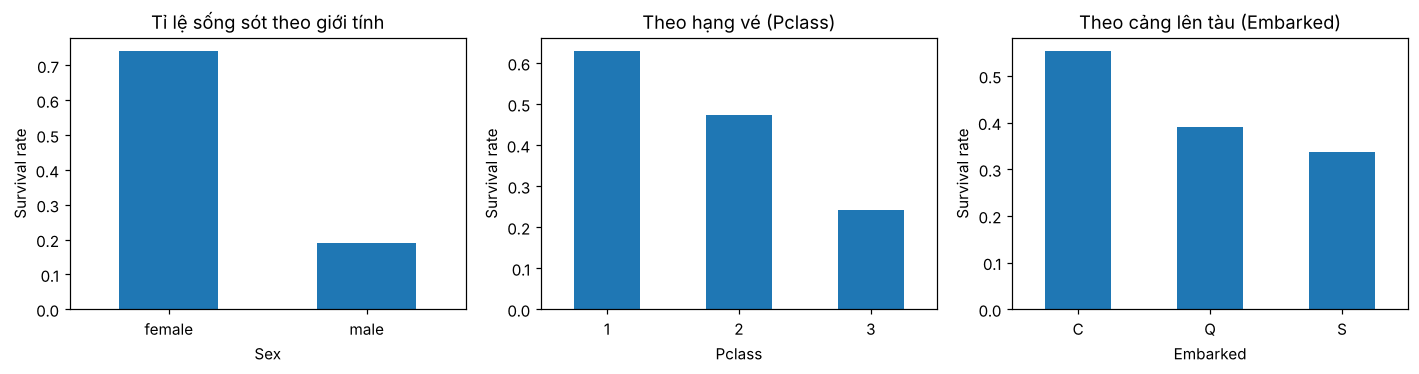

In [3]:
print('Tỉ lệ sống sót chung:', round(train['Survived'].mean(), 3))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
train.groupby('Sex')['Survived'].mean().plot.bar(ax=axs[0], title='Tỉ lệ sống sót theo giới tính', rot=0)
train.groupby('Pclass')['Survived'].mean().plot.bar(ax=axs[1], title='Theo hạng vé (Pclass)', rot=0)
train.groupby('Embarked')['Survived'].mean().plot.bar(ax=axs[2], title='Theo cảng lên tàu (Embarked)', rot=0)
for a in axs: a.set_ylabel('Survival rate')
plt.tight_layout(); plt.show()

**Nhận xét:** nữ giới và hành khách hạng 1 có tỉ lệ sống sót cao hơn hẳn; `Sex` và `Pclass` hứa hẹn là các đặc trưng quan trọng.

## 3. Tiền xử lý dữ liệu và tạo đặc trưng
Gộp train và test để xử lý đồng nhất, rồi tách lại.

| Bước | Cách xử lý |
|---|---|
| `Title` | Trích danh xưng (Mr, Mrs, Miss, Master…) từ `Name`, gộp các danh xưng hiếm |
| `Age` (thiếu) | Điền bằng trung vị của nhóm `Title` |
| `Fare` (thiếu 1) | Điền bằng trung vị theo `Pclass` |
| `Embarked` (thiếu 2) | Điền giá trị phổ biến nhất |
| `FamilySize`, `IsAlone` | Tạo từ `SibSp` + `Parch` |
| `Cabin`, `Ticket`, `Name`, `PassengerId` | Loại bỏ (thiếu quá nhiều hoặc không có giá trị dự đoán) |
| `Sex`, `Embarked`, `Title` | Mã hoá thành số |

In [4]:
full = pd.concat([train.drop(columns='Survived'), test], keys=['train', 'test'])

# Title
full['Title'] = full['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
full['Title'] = full['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
common = ['Mr', 'Mrs', 'Miss', 'Master']
full['Title'] = full['Title'].where(full['Title'].isin(common), 'Rare')

# Điền giá trị thiếu
full['Age'] = full['Age'].fillna(full.groupby('Title')['Age'].transform('median'))
full['Fare'] = full['Fare'].fillna(full.groupby('Pclass')['Fare'].transform('median'))
full['Embarked'] = full['Embarked'].fillna(full['Embarked'].mode()[0])

# Đặc trưng gia đình
full['FamilySize'] = full['SibSp'] + full['Parch'] + 1
full['IsAlone'] = (full['FamilySize'] == 1).astype(int)

# Mã hoá biến phân loại
full['Sex'] = full['Sex'].map({'male': 0, 'female': 1})
full['Embarked'] = full['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
full['Title'] = full['Title'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Master': 3, 'Rare': 4})

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title', 'FamilySize', 'IsAlone']
X_all = full[features]
print('Giá trị thiếu còn lại:', X_all.isna().sum().sum())

X = X_all.loc['train'].reset_index(drop=True)
y = train['Survived'].values
X_submit = X_all.loc['test'].reset_index(drop=True)
X.head()

Giá trị thiếu còn lại: 0


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone
0,3,0,22.0,1,0,7.2500,0,0,2,0
1,1,1,38.0,1,0,71.2833,1,1,2,0
2,3,1,26.0,0,0,7.9250,0,2,1,1
3,1,1,35.0,1,0,53.1000,0,1,2,0
4,3,0,35.0,0,0,8.0500,0,0,1,1


## 4. Chia tập huấn luyện / kiểm tra (80% / 20%)

In [5]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X.values, y, test_size=0.2, random_state=24, stratify=y)
print(X_train.shape, X_valid.shape)

(712, 10) (179, 10)


---
# Phần A. Cây quyết định

### A1. Cây đơn giản (`max_depth=3`) và trực quan hoá

Accuracy train: 0.8329 | valid: 0.8268


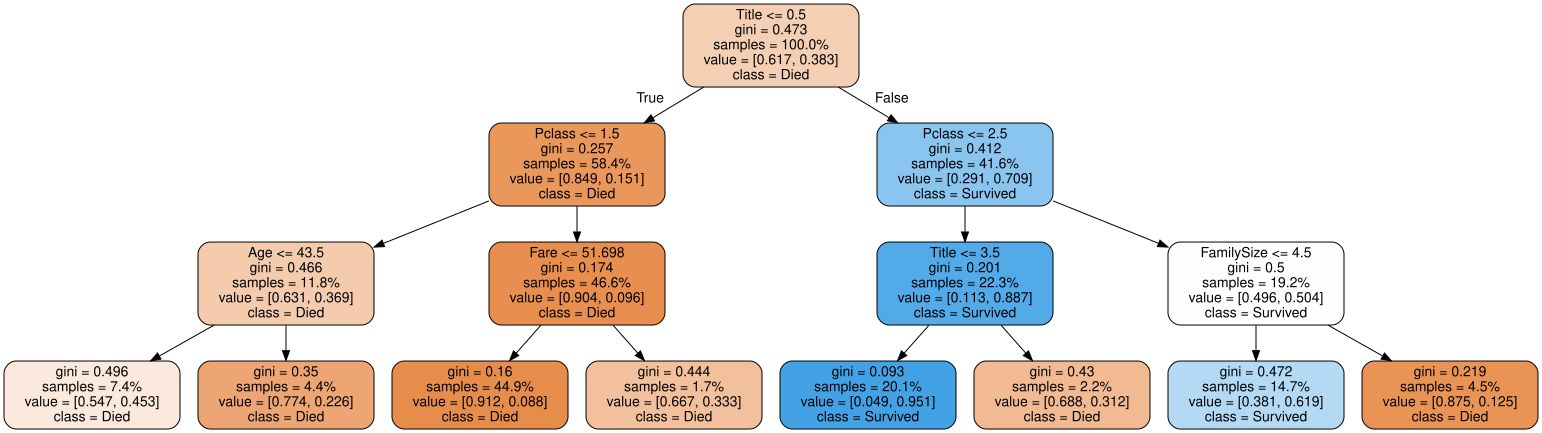

In [6]:
dt = tree.DecisionTreeClassifier(max_depth=3, random_state=24)
dt.fit(X_train, y_train)
print('Accuracy train:', round(dt.score(X_train, y_train), 4), '| valid:', round(dt.score(X_valid, y_valid), 4))

dot_data = tree.export_graphviz(dt, out_file=None, filled=True, rounded=True,
                                feature_names=features, proportion=True,
                                class_names=['Died', 'Survived'])
graphviz.Source(dot_data)

**Nhận xét:** nút gốc tách theo giới tính (`Sex`), sau đó là `Pclass`, `Age`/`Title`… Điều này khớp với EDA: giới tính và hạng vé là yếu tố phân biệt mạnh nhất.

### A2. Tìm `max_depth` tối ưu bằng GridSearchCV
`scoring='accuracy'` (nhãn tương đối cân bằng, 38% sống sót), `cv=5`, `return_train_score=True` để quan sát bias / variance.

In [7]:
params = {'max_depth': list(range(1, 13))}
cv_dt = GridSearchCV(tree.DecisionTreeClassifier(random_state=24), param_grid=params,
                     scoring='accuracy', cv=5, refit=True, return_train_score=True, verbose=1)
cv_dt.fit(X_train, y_train)
print('Tham số tốt nhất:', cv_dt.best_params_, '| Accuracy CV:', round(cv_dt.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits


Tham số tốt nhất: {'max_depth': 4} | Accuracy CV: 0.8229


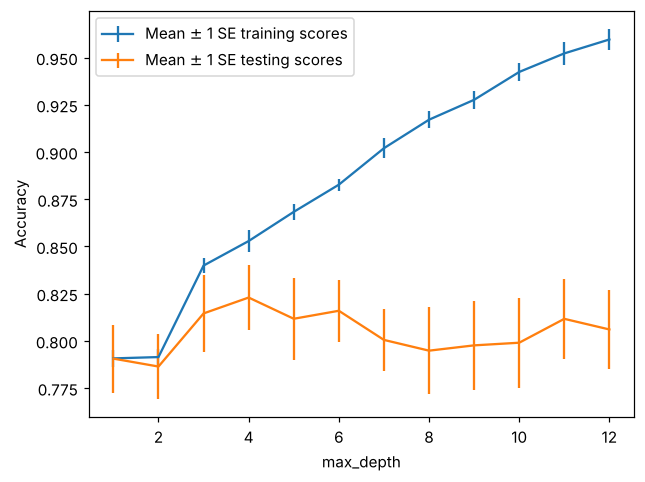

In [8]:
res = pd.DataFrame(cv_dt.cv_results_)
n = 5
ax = plt.axes()
ax.errorbar(res['param_max_depth'], res['mean_train_score'], yerr=res['std_train_score']/np.sqrt(n),
            label='Mean $\\pm$ 1 SE training scores')
ax.errorbar(res['param_max_depth'], res['mean_test_score'], yerr=res['std_test_score']/np.sqrt(n),
            label='Mean $\\pm$ 1 SE testing scores')
ax.legend(); plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.show()

**Nhận xét:** điểm train tăng gần tới 1.0 khi cây sâu, còn điểm test đạt đỉnh ở độ sâu nhỏ rồi giảm hoặc dao động → **quá khớp (overfitting)**. Nên chọn cây nông.

---
# Phần B. Rừng cây (Random Forest)

### B1. Tìm `n_estimators` và `max_depth` bằng GridSearchCV

In [9]:
rf = RandomForestClassifier(max_features='sqrt', bootstrap=True, random_state=4)
rf_params = {'n_estimators': list(range(10, 210, 20)), 'max_depth': [3, 5, 7, None]}
cv_rf = GridSearchCV(rf, param_grid=rf_params, scoring='accuracy', cv=5,
                     refit=True, return_train_score=True, verbose=1)
cv_rf.fit(X_train, y_train)
print('Tham số tốt nhất:', cv_rf.best_params_, '| Accuracy CV:', round(cv_rf.best_score_, 4))

Fitting 5 folds for each of 40 candidates, totalling 200 fits


Tham số tốt nhất: {'max_depth': 5, 'n_estimators': 70} | Accuracy CV: 0.8272


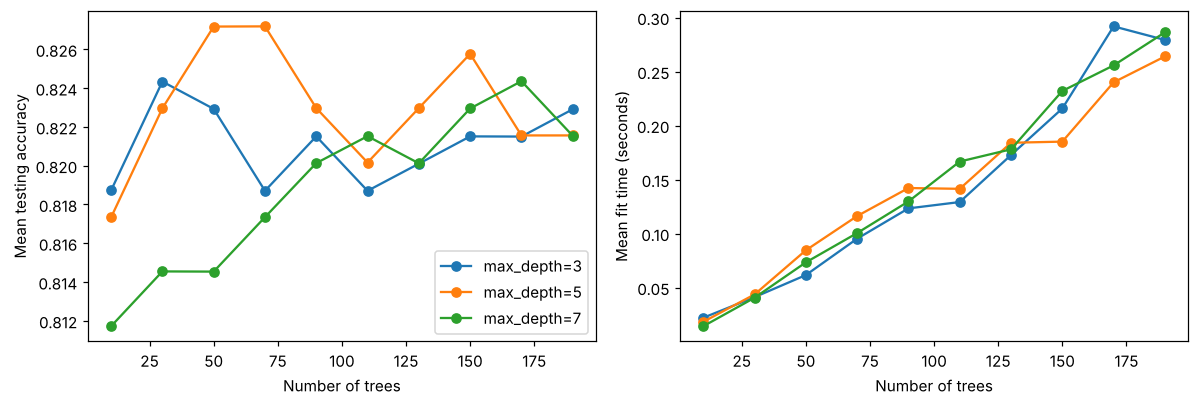

In [10]:
rr = pd.DataFrame(cv_rf.cv_results_)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for d, g in rr.groupby(rr['param_max_depth'].astype(str)):
    axs[0].plot(g['param_n_estimators'], g['mean_test_score'], '-o', label=f'max_depth={d}')
    axs[1].plot(g['param_n_estimators'], g['mean_fit_time'], '-o', label=f'max_depth={d}')
axs[0].set_xlabel('Number of trees'); axs[0].set_ylabel('Mean testing accuracy'); axs[0].legend()
axs[1].set_xlabel('Number of trees'); axs[1].set_ylabel('Mean fit time (seconds)')
plt.tight_layout(); plt.show()

### B2. Mức độ quan trọng của từng feature

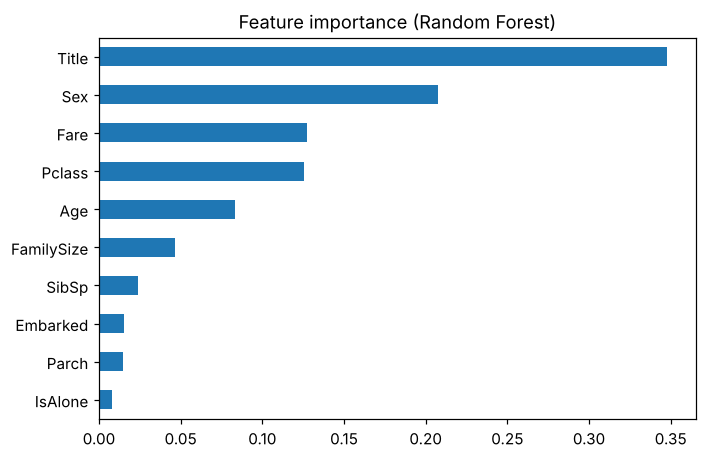

Title         0.3479
Sex           0.2077
Fare          0.1273
Pclass        0.1253
Age           0.0833
FamilySize    0.0466
SibSp         0.0237
Embarked      0.0154
Parch         0.0145
IsAlone       0.0083
dtype: float64

In [11]:
best_rf = cv_rf.best_estimator_
feat_imp = pd.Series(best_rf.feature_importances_, index=features).sort_values()
feat_imp.plot.barh(figsize=(7, 4.5), title='Feature importance (Random Forest)')
plt.show()
feat_imp.sort_values(ascending=False).round(4)

**Nhận xét:** `Title`, `Sex`, `Fare`, `Age`, `Pclass` đóng góp nhiều nhất. `Title` chứa thông tin về cả giới tính, độ tuổi và tình trạng hôn nhân nên thường đứng đầu. `Embarked` và `IsAlone` đóng góp ít.

---
# Phần C. Đánh giá và so sánh mô hình trên tập kiểm tra (20% giữ lại)

In [12]:
best_dt = cv_dt.best_estimator_
models = {'Decision Tree (depth=3)': dt, 'Decision Tree (tối ưu)': best_dt, 'Random Forest (tối ưu)': best_rf}
rows = [{'Mô hình': k, 'Accuracy train': m.score(X_train, y_train), 'Accuracy valid': m.score(X_valid, y_valid)}
        for k, m in models.items()]
pd.DataFrame(rows).round(4)

,Mô hình,Accuracy train,Accuracy valid
0,Decision Tree (depth=3),0.8329,0.8268
1,Decision Tree (tối ưu),0.8483,0.8212
2,Random Forest (tối ưu),0.8483,0.8324


              precision    recall  f1-score   support

        Died       0.84      0.90      0.87       110
    Survived       0.82      0.72      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



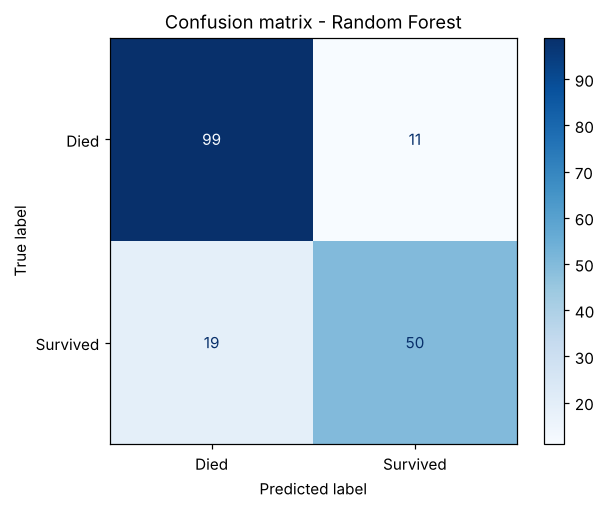

In [13]:
y_pred = best_rf.predict(X_valid)
print(classification_report(y_valid, y_pred, target_names=['Died', 'Survived']))
ConfusionMatrixDisplay(confusion_matrix(y_valid, y_pred), display_labels=['Died', 'Survived']).plot(cmap='Blues')
plt.title('Confusion matrix - Random Forest'); plt.show()

---
# Phần D. Dự đoán trên `test.csv` và so sánh với `gender_submission.csv`
Huấn luyện lại mô hình tốt nhất trên **toàn bộ** tập train (891 dòng) rồi dự đoán 418 hành khách của tập test.

> **Lưu ý:** `gender_submission.csv` **không phải đáp án thật**. Đây chỉ là file nộp mẫu của Kaggle, giả định "nữ sống, nam chết". Vì vậy ta chỉ so sánh mức độ **trùng khớp** với baseline này, không coi đó là accuracy. Muốn biết điểm thật cần nộp file lên Kaggle.

In [14]:
final_rf = RandomForestClassifier(**{**best_rf.get_params()})
final_rf.fit(X.values, y)

pred = final_rf.predict(X_submit.values)
submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': pred})
submission.to_csv('submission.csv', index=False)
print(submission['Survived'].value_counts().rename({0: 'Died', 1: 'Survived'}))

agree = (submission['Survived'].values == gender_sub['Survived'].values).mean()
print(f'Trùng khớp với baseline gender_submission: {agree:.1%}')
submission.head()

Survived
Died        254
Survived    164
Name: count, dtype: int64
Trùng khớp với baseline gender_submission: 94.3%


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


## Kết luận
- `Sex`, `Title` và `Pclass` là các yếu tố ảnh hưởng mạnh nhất tới khả năng sống sót ("phụ nữ và trẻ em trước", hành khách hạng cao được ưu tiên).
- Cây quyết định đơn dễ quá khớp khi tăng độ sâu; cần chọn `max_depth` bằng cross-validation.
- Random Forest cho kết quả ổn định hơn nhờ giảm phương sai; tối ưu thêm `n_estimators` và `max_depth`.
- Hướng cải tiến: thử thêm đặc trưng (ví dụ nhóm tuổi, deck từ `Cabin`), `RandomizedSearchCV`, hoặc các mô hình boosting.